# Chatbot And RAG Evaluation

Retrieval Augmented Generation (RAG) is a technique that enhances Large Language Models (LLMs) by providing them with relevant external knowledge. It has become one of the most widely used approaches for building LLM applications.

This tutorial will show you how to evaluate your RAG applications using LangSmith. You'll learn:

1. How to create test datasets
2. How to run your RAG application on those datasets
3. How to measure your application's performance using different evaluation metrics

### Overview
A typical RAG evaluation workflow consists of three main steps:

1. Creating a dataset with questions and their expected answers
2. Running your RAG application on those questions
3. Using evaluators to measure how well your application performed, looking at factors like:
 - Answer relevance
 - Answer accuracy
 - Retrieval quality
 
For this tutorial, we'll create and evaluate a bot that answers questions about a few of Lilian Weng's insightful blog posts.



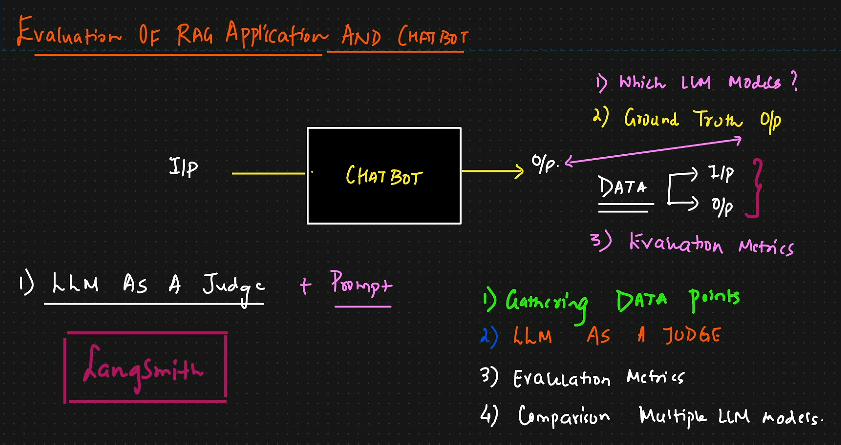

## **Chatbot Evaluation**

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["LANGSMITH_API_KEY"]=os.getenv("LANGSMITH_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
os.environ["LANGSMITH_TRACING"]="true"
# TO trace the requests to LangSmith, set LANGSMITH_TRACING to "true" in your environment variables. 
# This will log the requests and responses to LangSmith for debugging purposes.

In [3]:
# create the datapoints

from langsmith import Client

client = Client()

# Define dataset: these are your test cases
dataset_name = "Chatbott Evaluation"
dataset = client.create_dataset(dataset_name)
client.create_examples(
    dataset_id=dataset.id,
    examples=[
        {
            "inputs": {"question": "What is LangChain?"},
            "outputs": {"answer": "A framework for building LLM applications"},
        },
        {
            "inputs": {"question": "What is LangSmith?"},
            "outputs": {"answer": "A platform for observing and evaluating LLM applications"},
        },
        {
            "inputs": {"question": "What is OpenAI?"},
            "outputs": {"answer": "A company that creates Large Language Models"},
        },
        {
            "inputs": {"question": "What is Google?"},
            "outputs": {"answer": "A technology company known for search"},
        },
        {
            "inputs": {"question": "What is Mistral?"},
            "outputs": {"answer": "A company that creates Large Language Models"},
        }
    ]
)

{'example_ids': ['4c545074-8386-4233-b24f-355f4d95dc04',
  'e1b32970-d20e-403a-b172-ac1b1bd48443',
  'b42a5b46-0560-46e0-9785-67c02725df6f',
  '7caf4b5e-ba77-4982-9d6a-2e73bcc2753b',
  '678681eb-f085-4f51-acee-4d9e521da3e4'],
 'count': 5,
 'as_of': '2026-11-13T13:44:40.276228857Z'}

### Define Metrics (LLM As A Judge)


In [4]:
from google import genai
from langsmith import wrappers
import os 

gemini_client = wrappers.wrap_gemini(
    genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
)

eval_instructions = "You are an expert professor specialized in grading students' answers to questions."

def correctness(inputs:dict,outputs:dict, reference_outputs:dict)->bool:
      user_content = f"""You are grading the following question:
    {inputs['question']}
    Here is the real answer:
    {reference_outputs['answer']}
    You are grading the following predicted answer:
    {outputs['response']}
    Respond with CORRECT or INCORRECT:
    Grade:
    """
      response = gemini_client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=user_content,
        config={
            "system_instruction": eval_instructions,
            "temperature": 0
        }
    )

      return response.text.strip().upper() == "CORRECT"

C:\Users\SAKSHAM RAJ\AppData\Local\Temp\ipykernel_6900\3619489504.py:5: LangSmithBetaWarning: Function wrap_gemini is in beta.
  gemini_client = wrappers.wrap_gemini(


In [5]:
# Concisions- checks whether the actual output is less than 2x the length of the expected result.

def concision(outputs: dict, reference_outputs: dict) -> bool:
    return len(outputs["response"]) < 2 * len(reference_outputs["answer"])

### Run Evaluations

In [6]:
# Default instructions
default_instructions = """
Respond to the user's question in a short, concise manner (one short sentence).
"""

# Your chatbot application
def my_app(
    question: str,
    model: str = "gemini-3.5-flash-lite",
    instructions: str = default_instructions
) -> str:

    response = gemini_client.models.generate_content(
        model=model,
        contents=question,
        config={
            "system_instruction": instructions,
            "temperature": 0
        }
    )

    return response.text

In [7]:
# Target function for LangSmith
def ls_target(inputs: dict) -> dict:
    return {"response": my_app(inputs["question"])}

In [8]:
# Run evaluation
experiment_results = client.evaluate(
    ls_target,
    data=dataset_name,
    evaluators=[correctness, concision],
    experiment_prefix="gemini-3.5-flash-lite-chatbot"
)

View the evaluation results for experiment: 'gemini-3.5-flash-lite-chatbot-338d840a' at:
https://smith.langchain.com/o/ef43aa6d-68ec-4b1b-8303-62bd1f4c76e0/datasets/8e559154-a74e-4a69-9ea2-146be1f8b7f9/compare?selectedSessions=cfd90e23-f029-4ff8-b945-5c545872fcc5




In [24]:
# Call my_app for every datapoints
def ls_target(inputs: str) -> dict:
    return {"response": my_app(inputs["question"],model="gemini-3.6-flash")}

In [25]:
# Run our evaluation
experiment_results=client.evaluate(
    ls_target, ## Your AI system
    data=dataset_name,
    evaluators=[correctness,concision],
    experiment_prefix="gemini-3.6-flash-chatbott"
)

View the evaluation results for experiment: 'gemini-3.6-flash-chatbott-30e9ac5a' at:
https://smith.langchain.com/o/ef43aa6d-68ec-4b1b-8303-62bd1f4c76e0/datasets/8e559154-a74e-4a69-9ea2-146be1f8b7f9/compare?selectedSessions=e50f70dc-cfec-4783-8751-9e05599c5db6




# **Evaluation For RAG**

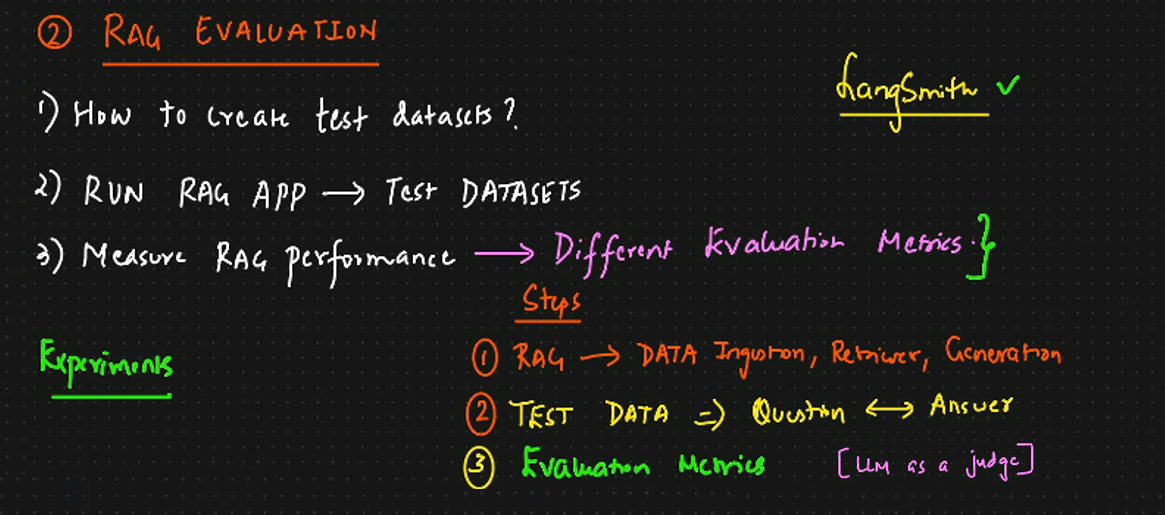
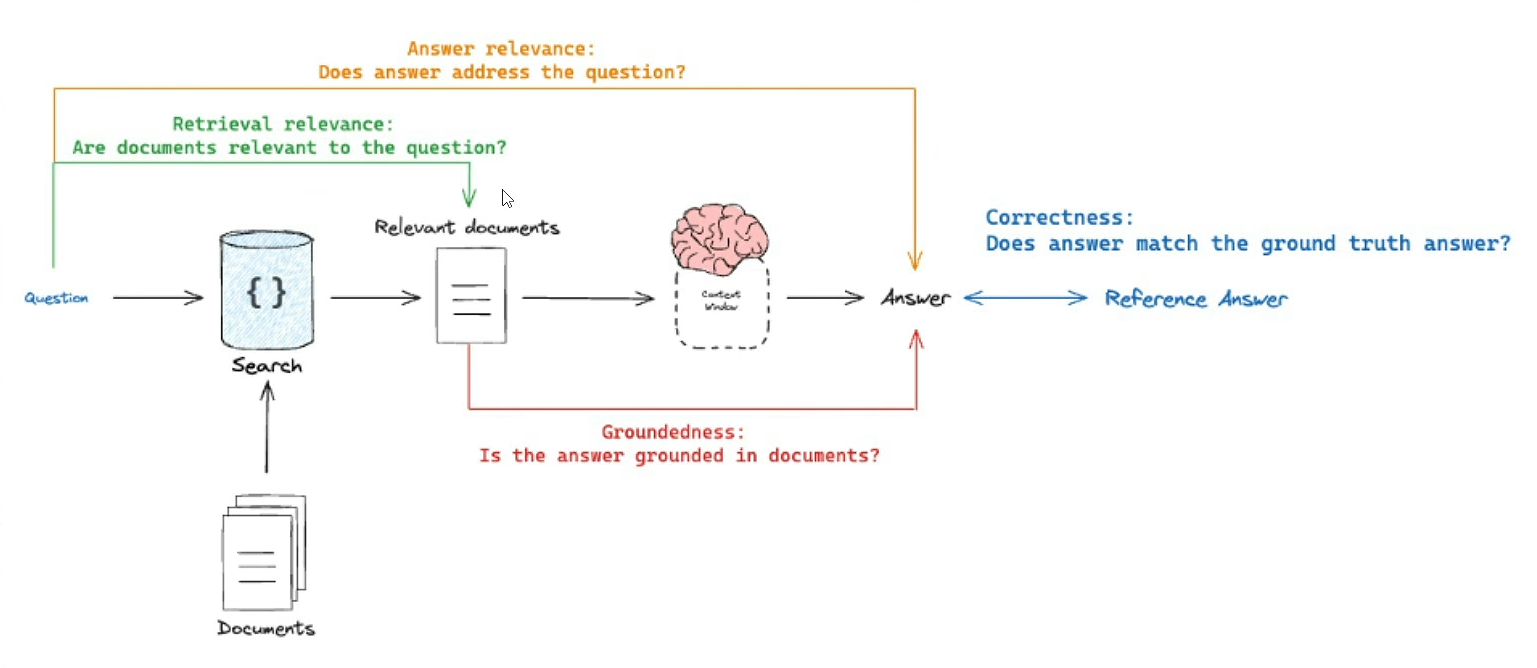

In [33]:
## RAG
import time

from langchain_community.document_loaders import WebBaseLoader
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 1. List of URLs to load documents from
urls = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/",
    "https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/",
]

# 2. Load documents from the URLs
docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

# 3. Initialize a text splitter with specified chunk size and overlap
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=250, chunk_overlap=0
)

# 4. Split the documents into chunks
doc_splits = text_splitter.split_documents(docs_list)

# 5. Embedding model initialization
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)

# 6. Add the document chunks to the "vector store" using GoogleGenerativeAIEmbeddings
vectorstore = InMemoryVectorStore(embedding=embeddings)

batch_size = 20

for i in range(0, len(doc_splits), batch_size):
    batch = doc_splits[i:i + batch_size]
    vectorstore.add_documents(batch)
    print(f"Processed {min(i + batch_size, len(doc_splits))}/{len(doc_splits)} documents")
    time.sleep(15)

# 7. With langchain we can easily turn any vector store into a retrieval component:
retriever = vectorstore.as_retriever(k=6)

Processed 20/187 documents
Processed 40/187 documents
Processed 60/187 documents
Processed 80/187 documents
Processed 100/187 documents
Processed 120/187 documents
Processed 140/187 documents
Processed 160/187 documents
Processed 180/187 documents
Processed 187/187 documents


In [34]:
result=retriever.invoke("What is an agent?")

In [35]:
result

[Document(id='e736f3d1-63ff-4751-aca4-f85bdb357cb7', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, 

In [36]:
for i, doc in enumerate(result):
    print(f"\nDocument {i+1}:")
    print(doc.page_content)


Document 1:
Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.
Agent System Overview#
In a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:

Planning

Subgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.
Reflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, thereby improving the quality of final results.


Memory

Document 2:
Short-term memory: I would consider all the in-context learning (See Prompt Engineering) as utilizing short-term memory 

In [44]:
from langchain.chat_models import init_chat_model
llm=init_chat_model("google_genai:gemini-3.5-flash-lite")
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0', 'langchain-google-genai': '4.5.0'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x0000015BF3C82F90>, default_metadata=(), model_kwar

In [ ]:
from langsmith import traceable

# Add decorator, the tracing will be automatically sent to LangSmith for analysis and debugging.
@traceable()
def rag_bot(question:str)->dict:
    ## Relevant context
    docs=retriever.invoke(question)
    docs_string = " ".join(doc.page_content for doc in docs)

    instructions = f"""You are a helpful assistant who is good at analyzing source information and answering questions.       
    Use the following source documents to answer the user's questions.       
    If you don't know the answer, just say that you don't know.       
    Use three sentences maximum and keep the answer concise.

Documents:
{docs_string}"""
    
    ## llm invoke

    ai_msg=llm.invoke([
         {"role": "system", "content": instructions},
        {"role": "user", "content": question},

    ])
    return {"answer":ai_msg.content,"documents":docs}



In [49]:
rag_bot("What is agent?")

{'answer': [{'type': 'text',
   'text': "An agent is a system built with a large language model (LLM) as its core controller, functioning as a powerful general problem solver. In an LLM-powered autonomous agent system, the LLM acts as the agent's brain. It is complemented by key components such as planning, memory, and tool use to handle complex tasks.",
   'extras': {'signature': 'EmAKXgFpFH0Taj8Iu4/zgzFnQg4VYcA+BhWeiDLfq09uwhMA7yNesZTIrYILPE7fraEHCk3KKqKSwUcBbE0x6ZihYp79LvTi9x4BMIbCioBzd0kkzxc6B1/33GZTTx3Ytgw='}}],
 'documents': [Document(id='e736f3d1-63ff-4751-aca4-f85bdb357cb7', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, 

In [53]:
response=rag_bot("What is agent?")
response["answer"][0]["text"]

'An LLM-powered autonomous agent is a system built with a large language model serving as its core controller or brain. This agent functions as a powerful general problem solver, complemented by key components such as planning, memory, and tool use'

### Test Dataset

In [55]:
from langsmith import Client

client=Client()

# Define the examples for the dataset
examples = [
    {
        "inputs": {"question": "How does the ReAct agent use self-reflection? "},
        "outputs": {"answer": "ReAct integrates reasoning and acting, performing actions - such tools like Wikipedia search API - and then observing / reasoning about the tool outputs."},
    },
    {
        "inputs": {"question": "What are the types of biases that can arise with few-shot prompting?"},
        "outputs": {"answer": "The biases that can arise with few-shot prompting include (1) Majority label bias, (2) Recency bias, and (3) Common token bias."},
    },
    {
        "inputs": {"question": "What are five types of adversarial attacks?"},
        "outputs": {"answer": "Five types of adversarial attacks are (1) Token manipulation, (2) Gradient based attack, (3) Jailbreak prompting, (4) Human red-teaming, (5) Model red-teaming."},
    }
]

# create the daatset and example in Langsmith
dataset_name="Learn RAG Test Evaluation"
dataset = client.create_dataset(dataset_name=dataset_name)
client.create_examples(
    dataset_id=dataset.id,
    examples=examples
)

{'example_ids': ['1d7720fa-c4ac-4cea-adfe-9f127bee01f9',
  '6608c699-a1ad-4ff8-ac46-3796e82ce327',
  '4e14350b-cb72-4f84-9b1c-ad9db1ab3cef'],
 'count': 3,
 'as_of': '2026-11-13T15:43:42.479237562Z'}

### Evaluators or Metrics



### 1. Correctness: Response vs Reference answer
- Goal: Measure "how similar/correct is the RAG chain answer, relative to a ground-truth answer"
- Mode: Requires a ground truth (reference) answer supplied through a dataset
- Evaluator: Use LLM-as-judge to assess answer correctness.

In [ ]:
from typing_extensions import Annotated, TypedDict

# Correctness Output Schema

# Grade output schema
class CorrectnessGrade(TypedDict):
    # Note that the order in the fields are defined is the order in which the model will generate them.
    # It is useful to put explanations before responses because it forces the model to think through
    # its final response before generating it:
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    correct: Annotated[bool, ..., "True if the answer is correct, False otherwise."]

# correctness prompt

correctness_instructions = """You are a teacher grading a quiz. 

You will be given a QUESTION, the GROUND TRUTH (correct) ANSWER, and the STUDENT ANSWER. 

Here is the grade criteria to follow:
(1) Grade the student answers based ONLY on their factual accuracy relative to the ground truth answer. 
(2) Ensure that the student answer does not contain any conflicting statements.
(3) It is OK if the student answer contains more information than the ground truth answer, as long as it is factually accurate relative to the  ground truth answer.

Correctness:
A correctness value of True means that the student's answer meets all of the criteria.
A correctness value of False means that the student's answer does not meet all of the criteria.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

from langchain_google_genai import ChatGoogleGenerativeAI

grader_llm=ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite").with_structured_output(
    CorrectnessGrade,
    method="json_schema",
    strict=True
)
# evaluator
def correctness(inputs: dict, outputs: dict, reference_outputs: dict) -> bool:
    """An evaluator for RAG answer accuracy"""
    answers = f"""\
QUESTION: {inputs['question']}
GROUND TRUTH ANSWER: {reference_outputs['answer']}
STUDENT ANSWER: {outputs['answer']}"""

    # Run evaluator
    grade = grader_llm.invoke([
        {"role": "system", "content": correctness_instructions}, 
        {"role": "user", "content": answers}
    ])
    return grade["correct"]

### 2. Relevance: Response vs Input 

Does the answer addresses the Input?

The flow is similar to above, but we simply look at the inputs and outputs without needing the reference_outputs. Without a reference answer we can't grade accuracy, but can still grade relevance—as in, did the model address the user's question or not.

In [57]:
# Grade output schema
class RelevanceGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    relevant: Annotated[bool, ..., "Provide the score on whether the answer addresses the question"]

# Grade prompt
relevance_instructions="""You are a teacher grading a quiz. 

You will be given a QUESTION and a STUDENT ANSWER. 

Here is the grade criteria to follow:
(1) Ensure the STUDENT ANSWER is concise and relevant to the QUESTION
(2) Ensure the STUDENT ANSWER helps to answer the QUESTION

Relevance:
A relevance value of True means that the student's answer meets all of the criteria.
A relevance value of False means that the student's answer does not meet all of the criteria.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

# Grader LLM
relevance_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite").with_structured_output(RelevanceGrade, method="json_schema", strict=True)

# Evaluator
def relevance(inputs: dict, outputs: dict) -> bool:
    """A simple evaluator for RAG answer helpfulness."""
    answer = f"QUESTION: {inputs['question']}\nSTUDENT ANSWER: {outputs['answer']}"
    grade = relevance_llm.invoke([
        {"role": "system", "content": relevance_instructions}, 
        {"role": "user", "content": answer}
    ])
    return grade["relevant"]

### 3. Groundedness: Response vs Retrieved docs

Is the answer grownded in the document?

Another useful way to evaluate responses without needing reference answers is to check if the response is justified by (or "grounded in") the retrieved documents.

In [58]:
# Grade output schema
class GroundedGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    grounded: Annotated[bool, ..., "Provide the score on if the answer hallucinates from the documents"]

# Grade prompt
grounded_instructions = """You are a teacher grading a quiz. 

You will be given FACTS and a STUDENT ANSWER. 

Here is the grade criteria to follow:
(1) Ensure the STUDENT ANSWER is grounded in the FACTS. 
(2) Ensure the STUDENT ANSWER does not contain "hallucinated" information outside the scope of the FACTS.

Grounded:
A grounded value of True means that the student's answer meets all of the criteria.
A grounded value of False means that the student's answer does not meet all of the criteria.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

# Grader LLM 
grounded_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite").with_structured_output(GroundedGrade, method="json_schema", strict=True)

# Evaluator
def groundedness(inputs: dict, outputs: dict) -> bool:
    """A simple evaluator for RAG answer groundedness."""
    doc_string = "\n\n".join(doc.page_content for doc in outputs["documents"])
    answer = f"FACTS: {doc_string}\nSTUDENT ANSWER: {outputs['answer']}"
    grade = grounded_llm.invoke([{"role": "system", "content": grounded_instructions}, {"role": "user", "content": answer}])
    return grade["grounded"]

### 4. Retrieval Relevance: Retrieved docs vs Input

In [59]:
# Grade output schema
class RetrievalRelevanceGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    relevant: Annotated[bool, ..., "True if the retrieved documents are relevant to the question, False otherwise"]

# Grade prompt
retrieval_relevance_instructions = """You are a teacher grading a quiz. 

You will be given a QUESTION and a set of FACTS provided by the student. 

Here is the grade criteria to follow:
(1) You goal is to identify FACTS that are completely unrelated to the QUESTION
(2) If the facts contain ANY keywords or semantic meaning related to the question, consider them relevant
(3) It is OK if the facts have SOME information that is unrelated to the question as long as (2) is met

Relevance:
A relevance value of True means that the FACTS contain ANY keywords or semantic meaning related to the QUESTION and are therefore relevant.
A relevance value of False means that the FACTS are completely unrelated to the QUESTION.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

# Grader LLM
retrieval_relevance_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite").with_structured_output(RetrievalRelevanceGrade, method="json_schema", strict=True)

def retrieval_relevance(inputs: dict, outputs: dict) -> bool:
    """An evaluator for document relevance"""
    doc_string = "\n\n".join(doc.page_content for doc in outputs["documents"])
    answer = f"FACTS: {doc_string}\nQUESTION: {inputs['question']}"

    # Run evaluator
    grade = retrieval_relevance_llm.invoke([
        {"role": "system", "content": retrieval_relevance_instructions}, 
        {"role": "user", "content": answer}
    ])
    return grade["relevant"]

### Run the evaluation

In [61]:
def target(inputs: dict) -> dict:
    return rag_bot(inputs["question"])

experiment_results = client.evaluate(
    target,
    data=dataset_name,
    evaluators=[correctness, groundedness, relevance, retrieval_relevance],
    experiment_prefix="rag-doc-relevance",
    metadata={"version": "LCEL context, gemini-3.5-flash-lite"},
)

View the evaluation results for experiment: 'rag-doc-relevance-af8d09f3' at:
https://smith.langchain.com/o/ef43aa6d-68ec-4b1b-8303-62bd1f4c76e0/datasets/917e45ff-a3fa-42a0-95d6-dee4de58c582/compare?selectedSessions=3af20707-fd83-47f5-9957-e3eba7be1808




In [62]:
# Explore results locally as a dataframe
# pandas must be installed

experiment_results.to_pandas()

,inputs.question,outputs.answer,outputs.documents,error,reference.answer,feedback.correctness,feedback.groundedness,feedback.relevance,feedback.retrieval_relevance,execution_time,example_id,id
0,What are the types of biases that can arise wi...,"[{'type': 'text', 'text': 'Based on the provid...",[page_content='References#\n[1] Zhao et al. “C...,None,The biases that can arise with few-shot prompt...,True,True,True,True,7.048059,1d7720fa-c4ac-4cea-adfe-9f127bee01f9,01a1d5a1-4a25-723d-8de1-104364578992
1,How does the ReAct agent use self-reflection?,"[{'type': 'text', 'text': 'Based on the provid...",[page_content='Self-reflection is a vital aspe...,None,"ReAct integrates reasoning and acting, perform...",True,True,True,True,5.391102,4e14350b-cb72-4f84-9b1c-ad9db1ab3cef,01a1d5a1-8c5b-772b-ae2c-913f0755e3e2
2,What are five types of adversarial attacks?,"[{'type': 'text', 'text': 'Based on the provid...",[page_content='Attack\nType\nDescription\n\n\n...,None,Five types of adversarial attacks are (1) Toke...,True,True,True,True,2.591206,6608c699-a1ad-4ff8-ac46-3796e82ce327,01a1d5a1-d19a-73f9-8a09-c371436da21f
